#  Trabajo Final Machine Learning
## Ejercicio 1: Regresión - Resistencia a compresión del hormigón
**Grupo:** A
**Integrantes:** [completar]
**Fecha:** 21-11-2026  
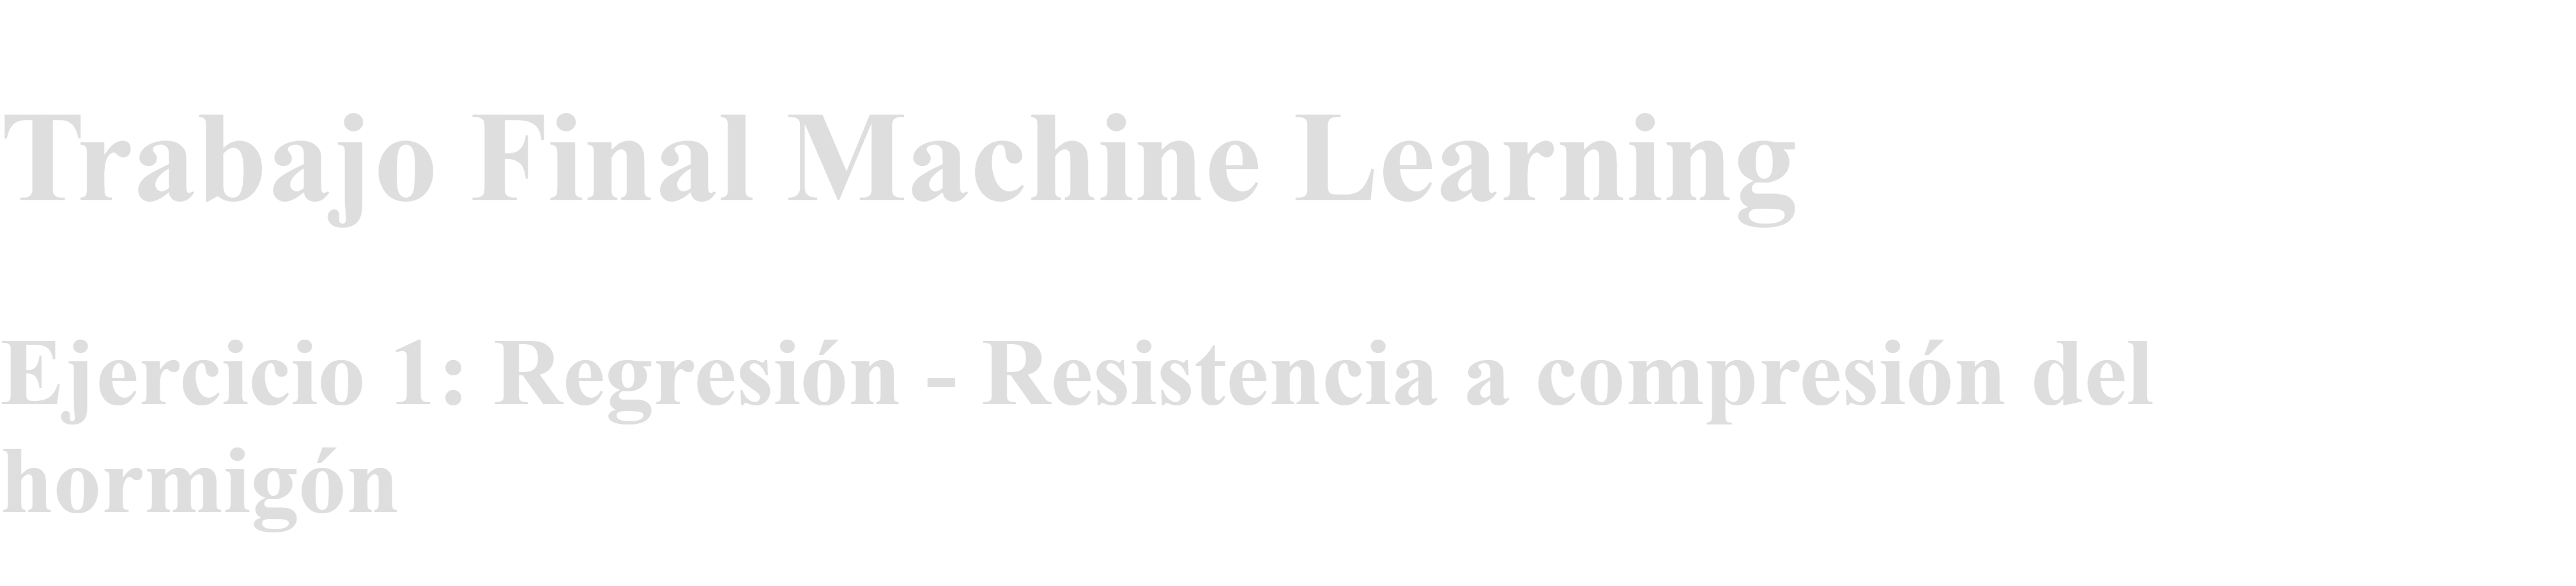

## Metadata

| Campo | Descripción |
|---|---|
| Fuente | UCI Machine Learning Repository, *Concrete Compressive Strength* (id 165) |
| Tipo de problema | Regresión (aprendizaje supervisado) |
| Variable objetivo | Resistencia a compresión del hormigón (MPa) |
| Variables predictoras | [completar luego de cargar los datos] |
| Cantidad de filas | [completar luego de cargar los datos] |
| Valores nulos | [completar luego del EDA] |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [2]:
concrete = fetch_ucirepo(id=165)

X = concrete.data.features   # variables predictoras
y = concrete.data.targets    # variable objetivo

print("Predictoras:", X.columns.tolist())
print("Objetivo:", y.columns.tolist())

Predictoras: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']
Objetivo: ['Concrete compressive strength']


In [4]:
df = pd.concat([X, y], axis=1)

df.columns = [
    "cemento", "escoria", "ceniza", "agua", "superplastificante",
    "agregado_grueso", "agregado_fino", "edad", "resistencia"
]

df.head()

,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cemento             1030 non-null   float64
 1   escoria             1030 non-null   float64
 2   ceniza              1030 non-null   float64
 3   agua                1030 non-null   float64
 4   superplastificante  1030 non-null   float64
 5   agregado_grueso     1030 non-null   float64
 6   agregado_fino       1030 non-null   float64
 7   edad                1030 non-null   int64  
 8   resistencia         1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


El dataset se compone de 1030 filas, no existen valores faltantes (non-null), todas las columnas son númericas (int64 y float64)

In [7]:
df.shape

(1030, 9)

In [9]:
display(df.describe().T.round(2))
print("Duplicados:", df.duplicated().sum())
print(df["edad"].value_counts().sort_index())

,count,mean,std,min,25%,50%,75%,max
cemento,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
escoria,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
ceniza,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
agua,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
superplastificante,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
agregado_grueso,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
agregado_fino,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
edad,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
resistencia,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


Duplicados: 25
edad
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


In [10]:
duplicadas = df[df.duplicated(keep=False)].sort_values(list(df.columns))
display(duplicadas)

,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30


Se identifican cuales son las filas duplicadas en el dataset.

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print("Nuevas dimensiones:", df.shape)

Nuevas dimensiones: (1005, 9)


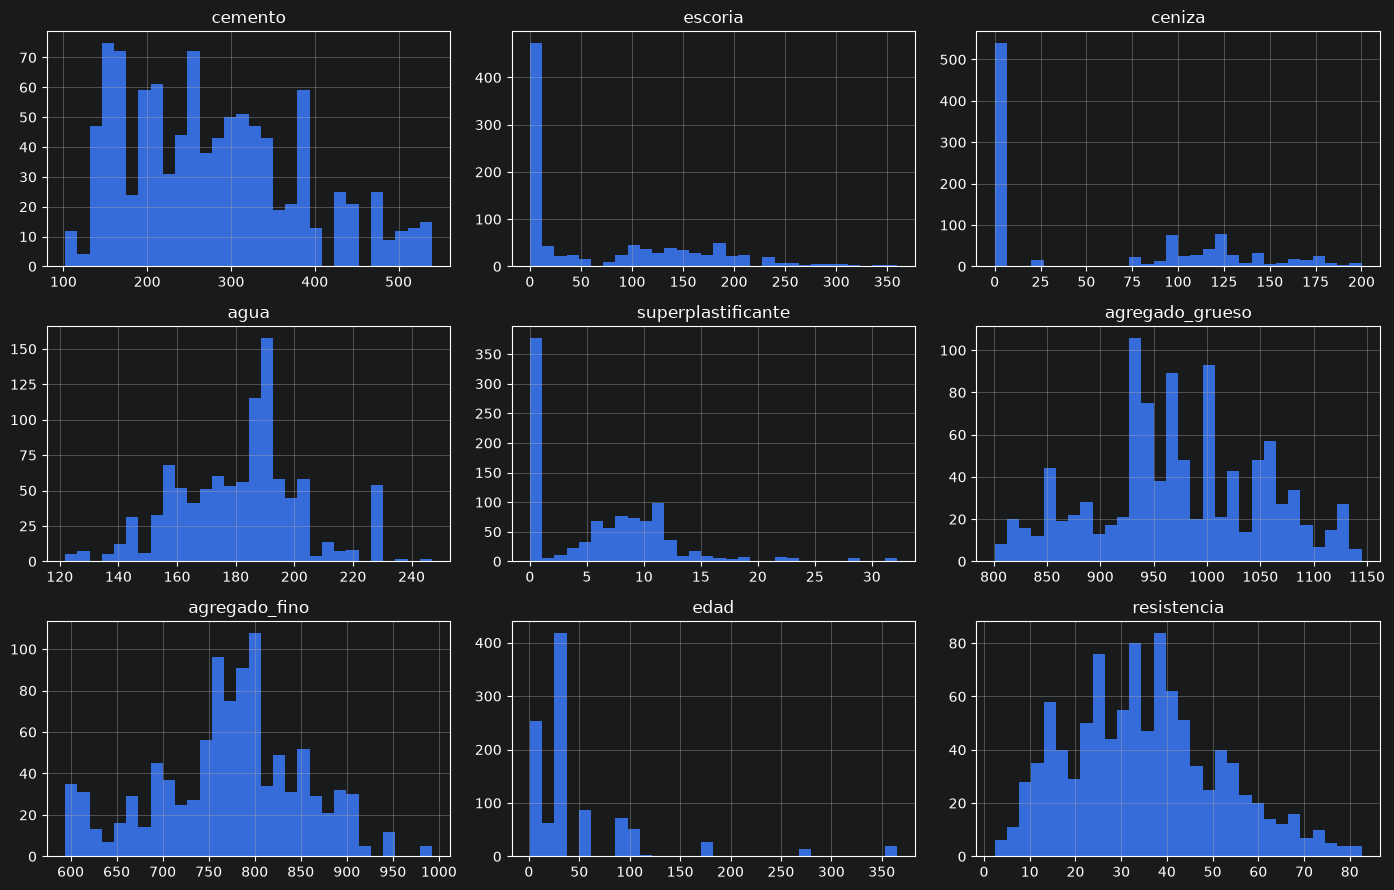

In [12]:
df.hist(bins=30, figsize=(14, 9))
plt.tight_layout()
plt.show()

El histograma muestra con qué frecuencia aparece cada rango de valores de una variable.
Pico fuerte en cero implica que son componentes que muchas mezclas no utilizan.
Forma que se aproximen a una campana indican distribución cercana a la normal.


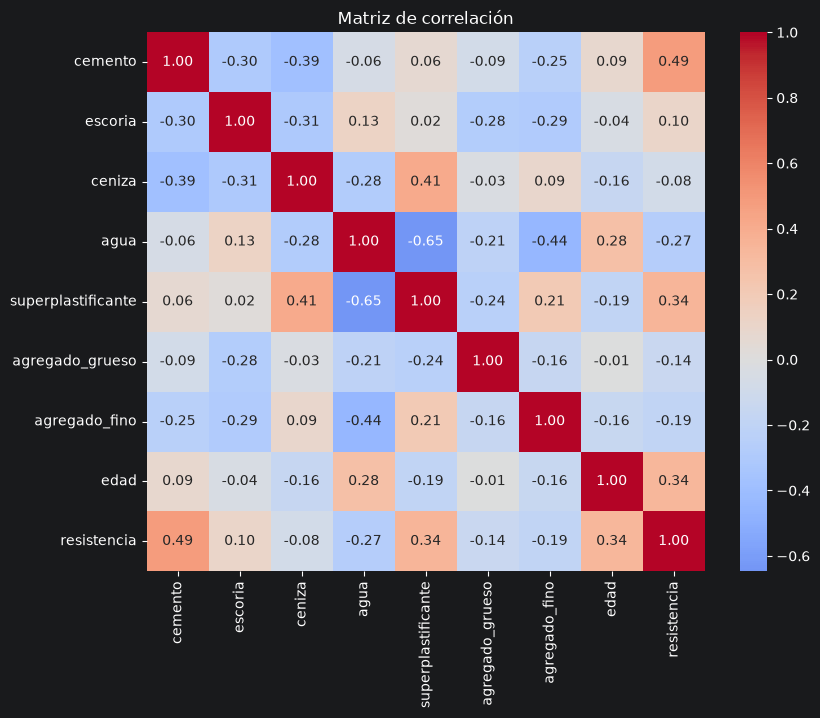

In [13]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

### Matriz de correlación

**¿Qué muestra?** La correlación de Pearson va entre cada par de variables.
Los valores son de -1 a +1: cerca de +1 las variables suben juntas, cerca de -1 una sube
cuando la otra baja, y cerca de 0 no hay relación lineal.

**Observaciones:**
- Ninguna variable supera 0,5 de correlación con la resistencia. La más alta
  es el cemento (0,49), seguida por el superplastificante y la edad (0,34).
  Ninguna variable explica por sí sola la resistencia: depende de la
  combinación de componentes.
- El agua tiene correlación negativa (-0,27): a mayor cantidad de agua, tiende
  a bajar la resistencia.
- La escoria (0,10) y la ceniza (-0,08) casi no tienen relación lineal con la
  resistencia, pero esto no implica que no influyan: muchas mezclas no las
  usan (valor 0) y la correlación de Pearson solo mide relaciones lineales.
- La correlación más fuerte entre predictoras es agua y superplastificante
  (-0,65). Es esperable, porque el aditivo permite reducir el agua. Es
  moderada y no se eliminan variables por esto.

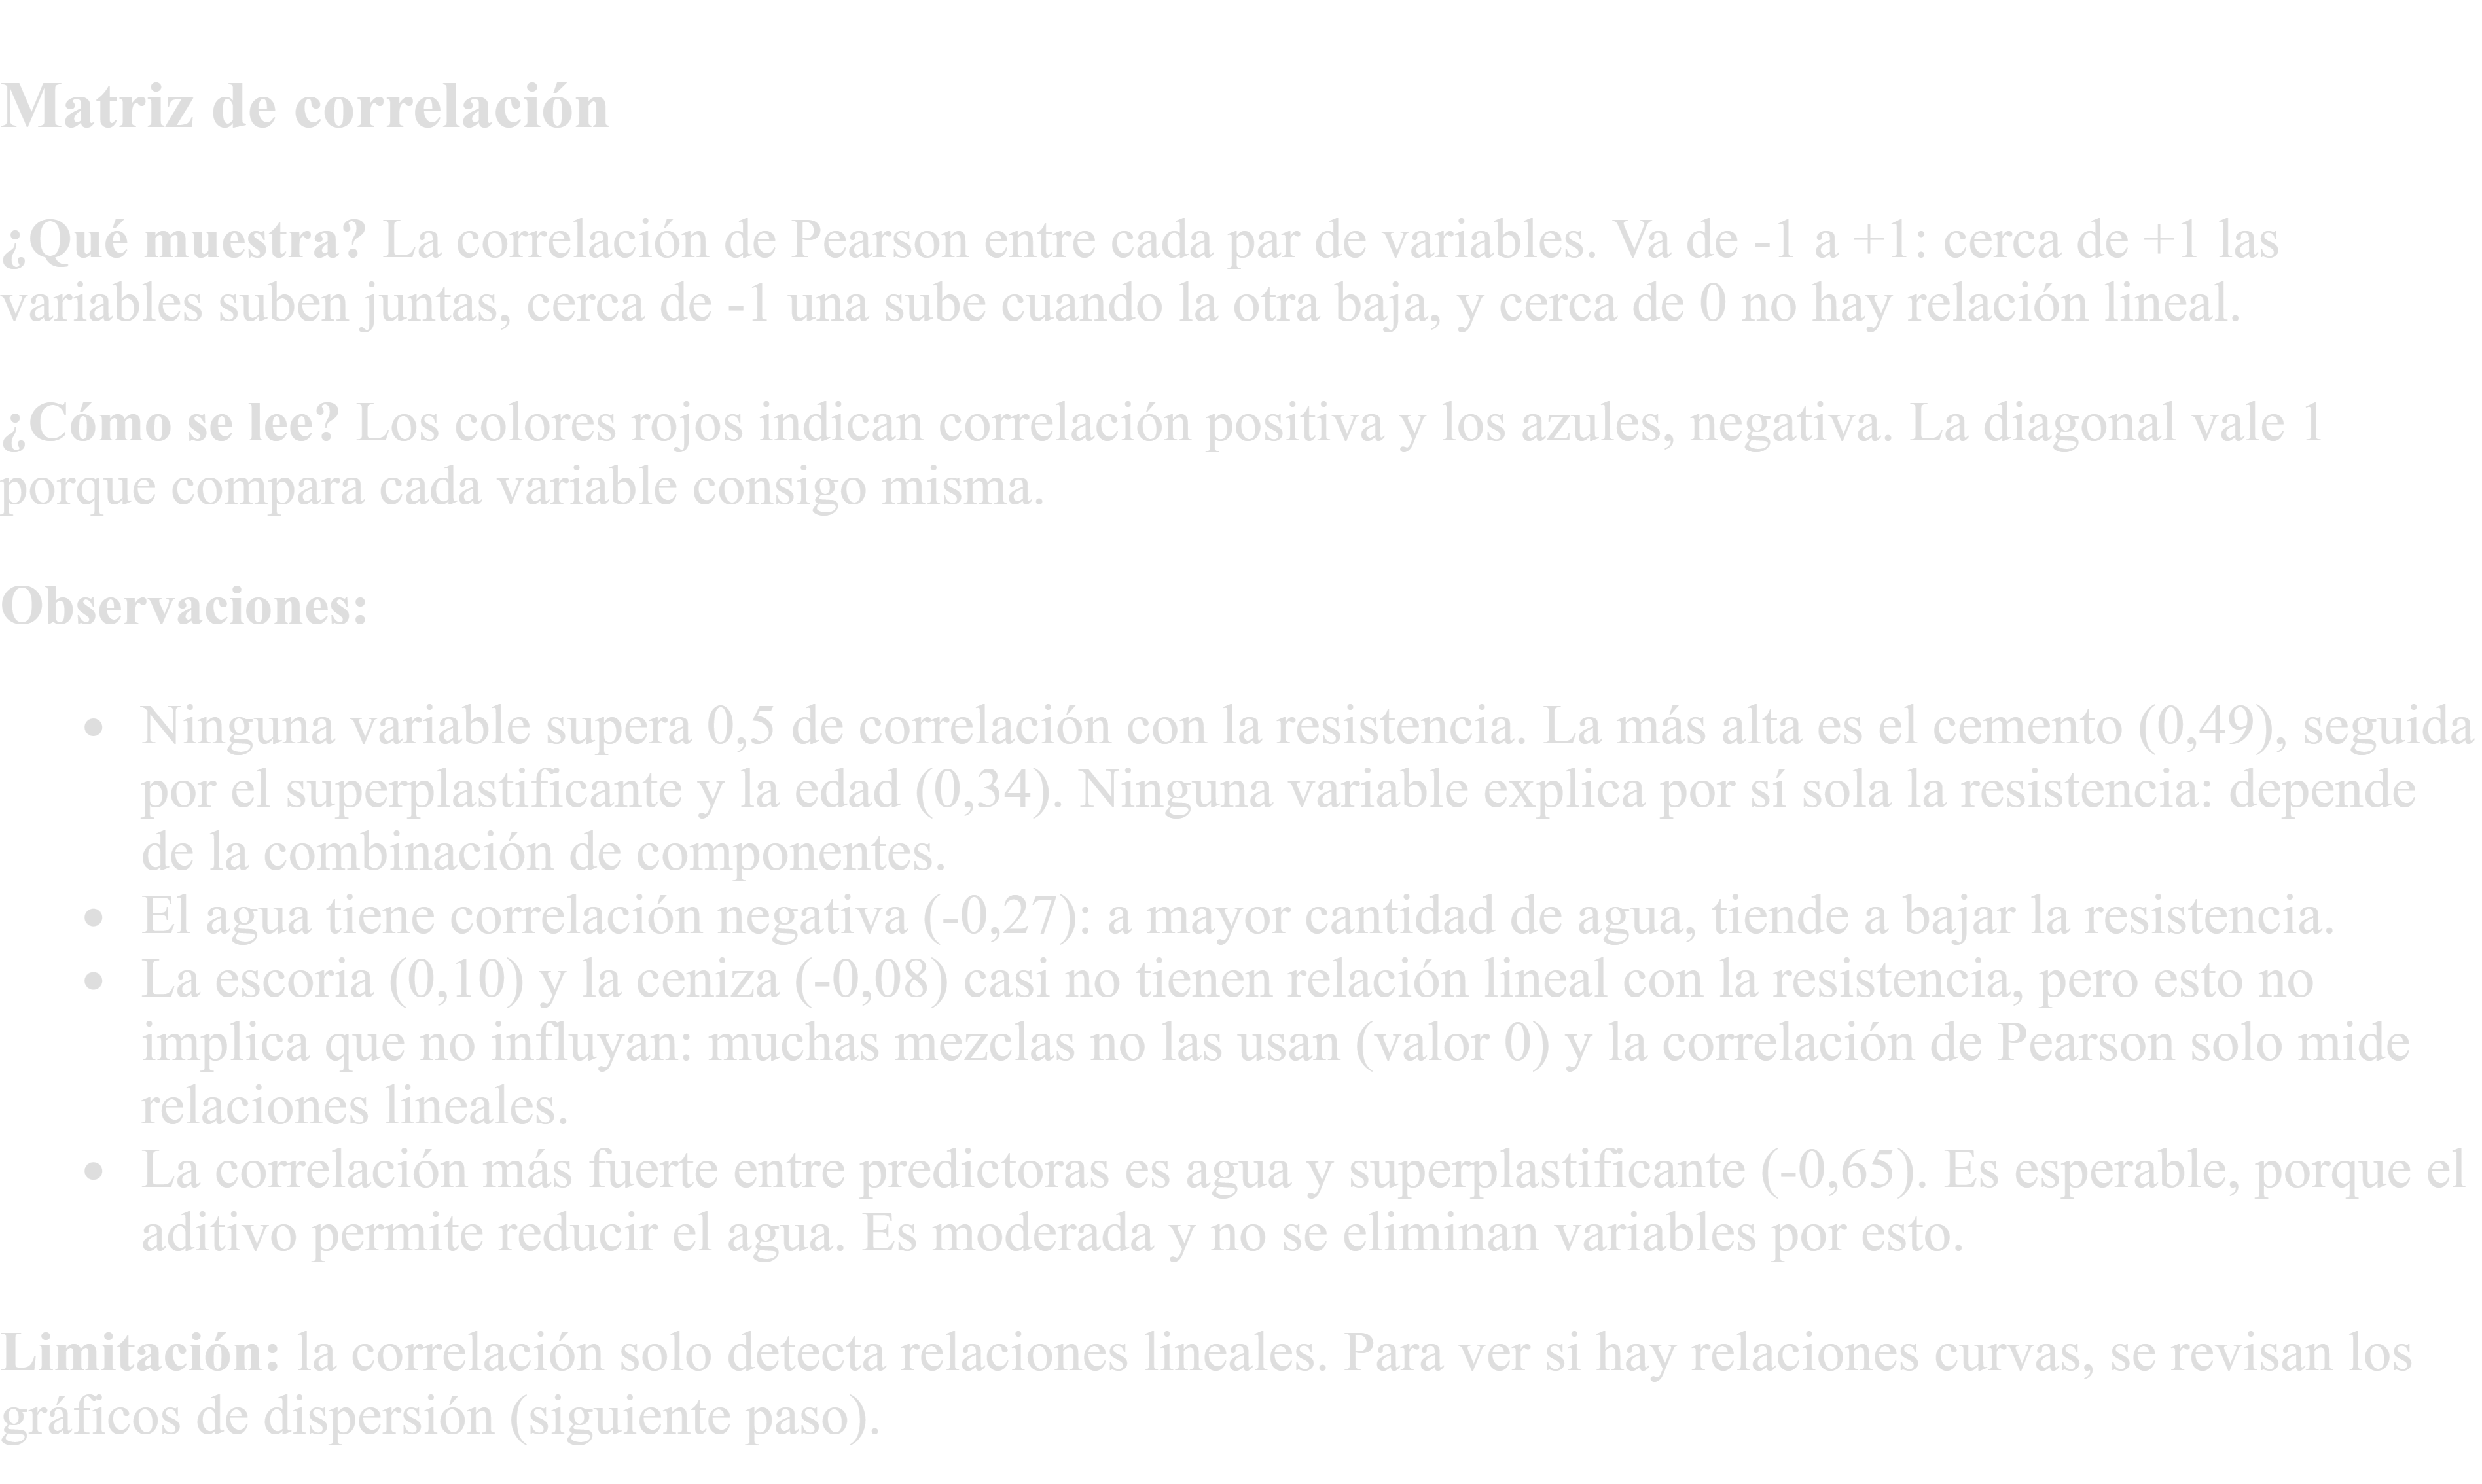